# Neural PDE Exercises · 06
## Build an independent solution audit

**Course section:** Checking a neural solution. **Time:** 35–50 minutes.
This notebook is self-contained: select **Restart Kernel and Run All Cells** in a
fresh Python 3.11+ kernel. CPU / float64; the supplied run is a working baseline.

[All practical exercises](README.md) · [Laboratory guide](../NOTEBOOK_README.md) ·
[Related laboratory](../Neural_PDE_02_poisson_and_limits.ipynb)

**How to work:** predict the outcome, run the baseline, then edit the marked
settings and rerun all cells. Keep a small results table and answer the reflection
questions. Use the same seed and training budget when comparing methods.

**Notation:** $u$ is the reference state, $u_\theta$ the neural state,
$r_\theta=\mathcal L u_\theta-f$, $\widehat{\mathcal J}$ a sampled loss,
and $\mathcal E$ an energy. Reference values are used for checking errors after
training, except when observations are explicitly supplied.

## 1 · Predict before computing

Train one hard-boundary PINN for the Poisson problem, then audit three candidates:
the learned state, that state plus an affine boundary error, and that state plus
a sine mode invisible to the training points. Adding $cx$ leaves $-u''$ unchanged;
adding $\varepsilon\sin((n+1)\pi x)$ preserves the boundaries but can hide between
collocation points $x_j=j/(n+1)$.

**Predict:** which diagnostic detects each perturbation? A useful report separates
training residual, independent residual, boundary error, and state error.

In [1]:
import copy
import math
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 7
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                 ["teal", "orange", "pink", "blue", "navy"]]),
})

def network(width=20, activation=nn.Tanh):
    return nn.Sequential(nn.Linear(1, width), activation(),
                         nn.Linear(width, width), activation(), nn.Linear(width, 1))

class State(nn.Module):
    def __init__(self, initial, hard=True):
        super().__init__()
        self.net, self.hard = copy.deepcopy(initial), hard
    def forward(self, x):
        raw = self.net(x)
        return x*(1-x)*raw if self.hard else raw

def derivative(value, x):
    return torch.autograd.grad(value.sum(), x, create_graph=True)[0]

def forcing(x):
    return math.pi**2 * torch.sin(math.pi*x)

def residual(model, points):
    x = points.detach().clone().requires_grad_(True)
    u = model(x)
    return -derivative(derivative(u, x), x) - forcing(x)

def train(model, objective, steps=500, lr=0.004):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    started = time.perf_counter()
    for step in range(steps):
        optimizer.zero_grad(set_to_none=True)
        loss = objective(model)
        loss.backward()
        optimizer.step()
        history.append(float(loss.detach()))
    assert np.isfinite(history).all(), "The optimizer produced a non-finite objective."
    return np.asarray(history), time.perf_counter()-started

# This independent grid is never passed to a training objective.
check_x = torch.linspace(0, 1, 503).reshape(-1, 1)
check_u = torch.sin(math.pi*check_x).numpy().ravel()
boundary_x = torch.tensor([[0.0], [1.0]])

def diagnostics(model):
    with torch.no_grad():
        prediction = model(check_x).numpy().ravel()
        boundary_error = float(model(boundary_x).abs().max())
    scaled_residual = residual(model, check_x).detach().numpy().ravel()/math.pi**2
    relative_l2 = np.linalg.norm(prediction-check_u)/np.linalg.norm(check_u)
    return {"prediction": prediction, "relative_l2": float(relative_l2),
            "residual_rms": float(np.sqrt(np.mean(scaled_residual**2))),
            "boundary_max": boundary_error}

print(f"CPU / float64 / seed {SEED} / PyTorch {torch.__version__}")

CPU / float64 / seed 7 / PyTorch 2.10.0


In [2]:
# EDIT HERE: keep the audit grid independent when changing training resolution.
N_COLLOCATION = 16
STEPS = 600
BOUNDARY_SHIFT = 0.1
HIDDEN_AMPLITUDE = 0.04
points = torch.arange(1, N_COLLOCATION+1).reshape(-1, 1)/(N_COLLOCATION+1)
trained = State(network())
history, seconds = train(trained, lambda m: (residual(m, points)/math.pi**2).square().mean(), STEPS)

class PerturbedState(nn.Module):
    def __init__(self, base, boundary_shift=0.0, hidden_amplitude=0.0):
        super().__init__()
        self.base = base
        self.boundary_shift = boundary_shift
        self.hidden_amplitude = hidden_amplitude
    def forward(self, x):
        return (self.base(x) + self.boundary_shift*x
                + self.hidden_amplitude*torch.sin((N_COLLOCATION+1)*math.pi*x))

candidates = {"Trained PINN": trained,
              "Affine boundary error": PerturbedState(trained, boundary_shift=BOUNDARY_SHIFT),
              "Hidden interior mode": PerturbedState(trained, hidden_amplitude=HIDDEN_AMPLITUDE)}
reports = {}
print(f"{'Candidate':24s} {'Train r RMS':>12s} {'Fresh r RMS':>12s} {'Boundary':>12s} {'Relative L2':>12s}")
for name, model in candidates.items():
    report = diagnostics(model)
    report["train_residual_rms"] = float((residual(model, points)/math.pi**2).square().mean().sqrt().detach())
    reports[name] = report
    print(f"{name:24s} {report['train_residual_rms']:12.3e} {report['residual_rms']:12.3e} "
          f"{report['boundary_max']:12.3e} {report['relative_l2']:12.3e}")
assert reports["Trained PINN"]["boundary_max"] == 0.0
assert np.isclose(reports["Affine boundary error"]["train_residual_rms"],
                  reports["Trained PINN"]["train_residual_rms"], atol=1e-10)
assert np.isclose(reports["Hidden interior mode"]["train_residual_rms"],
                  reports["Trained PINN"]["train_residual_rms"], atol=1e-9)

Candidate                 Train r RMS  Fresh r RMS     Boundary  Relative L2
Trained PINN                1.808e-03    4.879e-03    0.000e+00    9.620e-05
Affine boundary error       1.808e-03    4.879e-03    1.000e-01    8.184e-02
Hidden interior mode        1.808e-03    8.167e+00    5.883e-17    4.001e-02


## 2 · Add a classical reference and refine it

A finite-difference solution provides a second route to the state. Use $n$ interior
nodes, spacing $h=1/(n+1)$, and the tridiagonal stencil $(-1,2,-1)/h^2$.
Report error at its own nodes separately from error after interpolation to the
audit grid. This is a correctness comparison, not an equal-cost benchmark.

FD n= 15 | node relative L2 3.219e-03 | interpolated relative L2 1.444e-03
FD n= 31 | node relative L2 8.036e-04 | interpolated relative L2 3.596e-04
FD n= 63 | node relative L2 2.008e-04 | interpolated relative L2 8.983e-05
Observed node-error order: 2.002
Observed node-error order: 2.001


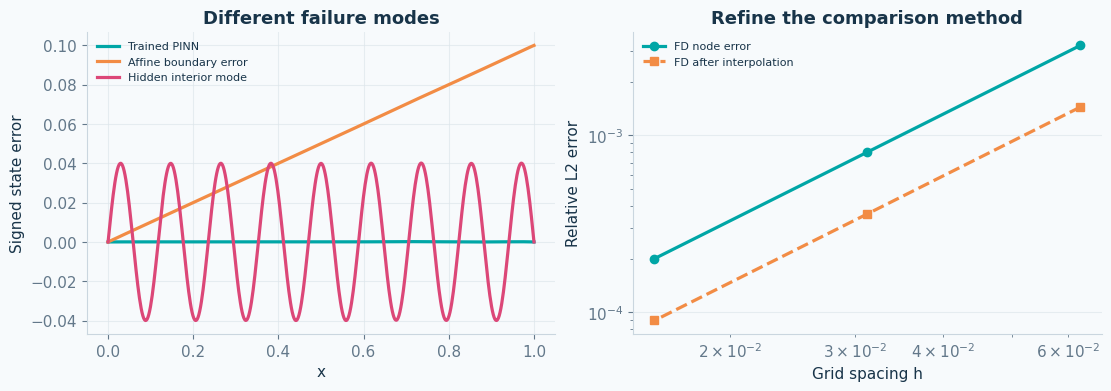

In [3]:
FD_COUNTS = [15, 31, 63]          # EDIT HERE: refine the reference independently.
fd_reports = []
for count in FD_COUNTS:
    nodes = np.linspace(0, 1, count+2)
    h = 1/(count+1)
    matrix = (2*np.eye(count)-np.eye(count, k=1)-np.eye(count, k=-1))/h**2
    interior = np.linalg.solve(matrix, np.pi**2*np.sin(np.pi*nodes[1:-1]))
    values = np.r_[0.0, interior, 0.0]
    truth = np.sin(np.pi*nodes)
    node_error = np.linalg.norm(values-truth)/np.linalg.norm(truth)
    interpolated = np.interp(check_x.numpy().ravel(), nodes, values)
    audit_error = np.linalg.norm(interpolated-check_u)/np.linalg.norm(check_u)
    fd_reports.append((h, node_error, audit_error))
    print(f"FD n={count:3d} | node relative L2 {node_error:.3e} | interpolated relative L2 {audit_error:.3e}")
for previous, current in zip(fd_reports[:-1], fd_reports[1:]):
    order = np.log(previous[1]/current[1])/np.log(previous[0]/current[0])
    print(f"Observed node-error order: {order:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for name, report in reports.items():
    axes[0].plot(check_x, report["prediction"]-check_u, label=name)
axes[0].set(title="Different failure modes", xlabel="x", ylabel="Signed state error")
axes[1].loglog([r[0] for r in fd_reports], [r[1] for r in fd_reports], "o-", label="FD node error")
axes[1].loglog([r[0] for r in fd_reports], [r[2] for r in fd_reports], "s--", label="FD after interpolation")
axes[1].set(title="Refine the comparison method", xlabel="Grid spacing h", ylabel="Relative L2 error")
for ax in axes:
    ax.grid(); ax.legend(fontsize=8)
plt.show()
assert np.isfinite(np.array(fd_reports)).all()

## 3 · Your audit and reflection

1. Increase the held-out grid from 503 to 1009 points in the setup. Check whether
   the diagnostics stabilize. Also evaluate the residual at independent random points.
2. Propose separate acceptance tolerances for boundary values, independent residual,
   and state error. Report which candidates pass each test and explain your choices.
3. Remove access to the analytic reference in your report. Which evidence remains?
   Explain why agreement with a refined classical solver is useful but is not a
   universal proof of accuracy for an arbitrary neural PDE solution.
4. Repeat training with three seeds. Distinguish variability across training runs
   from changes caused by refining the validation grid.

**Hint:** a residual-to-solution error estimate also needs stability, the correct
boundary conditions, and appropriate norms. The assertions above verify the
constructed failure modes; they are not an accuracy certificate for the PINN.

**Deliverable:** a compact audit table, a reference-refinement plot, and a statement
of what you can and cannot conclude without an exact solution.